# Como o Senado vota? Análise das votações nominais de 2025

Este notebook extrai, trata e analisa dados da
[API de Dados Abertos do Senado Federal](https://legis.senado.leg.br/dadosabertos/api-docs/swagger-ui/index.html),
com foco nas **votações nominais do Plenário em 2025**.

## 1. Configuração

Bibliotecas e parâmetros usados em todo o notebook. `PAUSA` espaça as requisições para não
sobrecarregar a API pública.

In [1]:
# Bibliotecas da extração: `requests` faz as chamadas HTTP; `Retry` e `HTTPAdapter` repetem
# automaticamente as chamadas que falham por instabilidade do servidor
import logging
import time
from typing import Any

import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

# Parâmetros da execução: para analisar outro ano, basta trocar ANO e rodar o notebook de novo
ANO: int = 2025
BASE_URL: str = "https://legis.senado.leg.br/dadosabertos"
TIMEOUT: int = 30   # segundos de espera máxima por resposta
PAUSA: float = 0.2  # intervalo entre requisições, para não sobrecarregar a API pública

# Mensagens de progresso e de erro com data e hora.
# force=True é necessário porque o Jupyter já configura o logging; sem ele, nada seria exibido.
logging.basicConfig(level=logging.INFO, format="%(asctime)s [%(levelname)s] %(message)s", force=True)
log = logging.getLogger("senado")

## 2. Cliente da API

Ao explorar a API, encontramos quatro comportamentos que o cliente precisa tratar:

| Comportamento observado | Tratamento |
|---|---|
| Sem o cabeçalho `Accept: application/json`, a API responde em **XML** | A sessão envia o cabeçalho em toda requisição |
| Um código inexistente (ex.: `/senador/99999999`) retorna **HTTP 200** só com metadados, sem erro | `extrair()` devolve lista vazia quando o caminho não existe |
| Cada endpoint aninha os dados de um jeito (`ListaParlamentarEmExercicio → Parlamentares → Parlamentar`, lista simples em `/votacao`...) e, por herança do XML, **um item único pode vir como objeto em vez de lista** | `extrair()` percorre o caminho informado e sempre devolve `list[dict]` |
| Endpoints documentados que respondem **404** (ex.: `/plenario/votacao/orientacaoBancada/{inicio}/{fim}`) | Erros HTTP viram `ErroAPI`, com mensagem clara |

Além disso, a sessão faz até 5 novas tentativas com *backoff* exponencial em erros transitórios
(`429` e `5xx`).

In [2]:
class ErroAPI(Exception):
    """Falha ao consultar a API do Senado (rede, HTTP ou resposta inválida)."""


# Sessão HTTP reutilizada em todas as chamadas (reaproveita a conexão, o que é mais rápido).
# Erros temporários (429 = muitas requisições; 5xx = falha no servidor) são repetidos até 5 vezes,
# com espera crescente entre as tentativas: 1s, 2s, 4s...
def criar_sessao() -> requests.Session:
    sessao = requests.Session()
    retry = Retry(
        total=5,
        backoff_factor=1,
        status_forcelist=[429, 500, 502, 503, 504],
        allowed_methods=["GET"],
        respect_retry_after_header=True,  # se a API disser quanto esperar, obedece
    )
    sessao.mount("https://", HTTPAdapter(max_retries=retry))
    # sem este cabeçalho a API responde em XML
    sessao.headers.update({"Accept": "application/json", "User-Agent": "desafio-aleon/1.0"})
    return sessao


# Ponto único de acesso à API: faz o GET e devolve o JSON já convertido para dict/list.
# Cada tipo de falha da biblioteca `requests` vira uma ErroAPI com mensagem clara, para que quem
# chama trate um único tipo de exceção e decida se aborta ou só registra a falha.
def get_json(sessao: requests.Session, endpoint: str, params: dict[str, Any] | None = None) -> Any:
    url = f"{BASE_URL}{endpoint}"
    try:
        resposta = sessao.get(url, params=params, timeout=TIMEOUT)
        resposta.raise_for_status()  # transforma respostas 4xx/5xx em exceção
        return resposta.json()
    except requests.exceptions.Timeout as e:
        raise ErroAPI(f"Timeout após {TIMEOUT}s: {url}") from e
    except requests.exceptions.RetryError as e:  # as 5 tentativas falharam
        raise ErroAPI(f"Tentativas esgotadas: {url}") from e
    except requests.exceptions.ConnectionError as e:
        raise ErroAPI(f"Falha de conexão: {url}") from e
    except requests.exceptions.HTTPError as e:
        raise ErroAPI(f"HTTP {e.response.status_code}: {url}") from e
    except ValueError as e:  # o corpo não é JSON (ex.: página de erro em HTML)
        raise ErroAPI(f"Resposta não é JSON válido: {url}") from e
    finally:
        time.sleep(PAUSA)  # roda com ou sem erro: garante o intervalo entre requisições


# Cada endpoint aninha os dados de um jeito, ex.: ListaParlamentarEmExercicio -> Parlamentares
# -> Parlamentar. Esta função desce pelas chaves informadas e SEMPRE devolve uma lista:
#   - caminho inexistente (ex.: senador que não existe) -> lista vazia
#   - item único que a API manda como objeto, e não como lista -> lista com um item
def extrair(payload: Any, *caminho: str) -> list[dict]:
    no = payload
    for chave in caminho:
        if not isinstance(no, dict) or chave not in no:
            return []
        no = no[chave]
    if no is None:
        return []
    return no if isinstance(no, list) else [no]

### 2.1 Validação do cliente

Dois testes dos casos de borda descritos acima. Os casos normais são exercitados pela própria
extração, na seção 3.

In [3]:
sessao = criar_sessao()  # a mesma sessão é usada até o fim do notebook

# Teste 1: código de senador inexistente. A API responde HTTP 200 (sucesso) mas sem dados;
# o esperado é uma lista vazia, sem erro
inexistente = extrair(get_json(sessao, "/senador/99999999"), "DetalheParlamentar", "Parlamentar")
print(f"Senador inexistente: {inexistente}")

# Teste 2: endpoint que consta na documentação mas responde 404. O esperado é uma ErroAPI
# com mensagem clara, capturada aqui sem interromper o notebook
try:
    get_json(sessao, f"/plenario/votacao/orientacaoBancada/{ANO}-03-01/{ANO}-03-31")
except ErroAPI as e:
    print(f"Erro tratado: {e}")

Senador inexistente: []


Erro tratado: HTTP 404: https://legis.senado.leg.br/dadosabertos/plenario/votacao/orientacaoBancada/2025-03-01/2025-03-31


## 3. Extração

### 3.1 Seleção dos dados

A pergunta central é **como o Senado vota**: quem vota com quem e como cada grupo reage às
propostas de outros grupos. Para isso, extraímos três conjuntos:

| Conjunto | Endpoint | Por que |
|---|---|---|
| Votações nominais de 2025, com o voto de cada senador | `/votacao` | Base de toda a análise; **uma única chamada** traz as 128 votações e os votos |
| Senadores em exercício | `/senador/lista/atual` | Perfil (sexo, UF) e **bloco parlamentar** de cada partido |
| Autoria das propostas votadas | `/processo/{id}` | Quem propôs cada matéria (Governo, Câmara, Senado) e de qual partido |

**Dados avaliados e descartados:**

- **Licenças** (`/senador/{codigo}/licencas`): seriam 81 chamadas, mas são redundantes. O próprio
  registro de cada voto já informa o motivo da ausência (licença saúde, missão oficial, não compareceu).
- **Filiações partidárias**: o voto já traz o partido do senador **na data da votação**, o que basta
  para identificar trocas de partido ao longo do ano.
- **Projetos de lei e discursos**: fogem do foco nas votações.

### 3.2 Funções de extração

Falhas pontuais (a autoria de uma proposta) são registradas em `falhas` e **não interrompem** a
extração. Já as votações e os senadores são essenciais: se falharem, a extração é abortada.

In [4]:
# Lista das falhas não fatais (ex.: autoria de uma proposta que não pôde ser obtida).
# É exibida ao fim da extração, para que nada falhe em silêncio.
falhas: list[dict] = []  # reiniciada a cada execução desta célula


def registrar_falha(etapa: str, chave: Any, erro: Exception) -> None:
    """Guarda uma falha não fatal para o relatório ao fim da extração."""
    log.warning("Falha em %s (%s): %s", etapa, chave, erro)
    falhas.append({"etapa": etapa, "chave": chave, "erro": str(erro)})


def extrair_votacoes(sessao: requests.Session, ano: int) -> list[dict]:
    """Votações nominais do Plenário no ano, cada uma com a lista de votos dos senadores."""
    # uma única chamada traz o ano inteiro, já com o voto de cada senador em cada votação
    votacoes = get_json(sessao, "/votacao", {"dataInicio": f"{ano}-01-01", "dataFim": f"{ano}-12-31"})
    if not isinstance(votacoes, list):  # protege contra mudança no formato da API
        raise ErroAPI(f"Formato inesperado em /votacao: {type(votacoes).__name__}")
    return votacoes


def extrair_senadores(sessao: requests.Session) -> list[dict]:
    """Senadores em exercício, com partido, UF e bloco parlamentar."""
    payload = get_json(sessao, "/senador/lista/atual")
    return extrair(payload, "ListaParlamentarEmExercicio", "Parlamentares", "Parlamentar")


def extrair_autorias(sessao: requests.Session, ids_processo: list[int]) -> dict[int, list[dict]]:
    """Autores (de iniciativa) de cada processo legislativo, indexados pelo id do processo."""
    # a autoria não vem na votação: é preciso consultar o detalhe de cada proposta (1 chamada cada)
    autorias: dict[int, list[dict]] = {}
    for i, id_processo in enumerate(ids_processo, 1):
        try:
            autorias[id_processo] = get_json(sessao, f"/processo/{id_processo}").get("autoriaIniciativa") or []
        except (ErroAPI, AttributeError) as e:  # AttributeError: resposta veio em formato inesperado
            registrar_falha("autoria", id_processo, e)  # segue para a próxima proposta
        if i % 25 == 0:  # progresso a cada 25 propostas
            log.info("Autorias: %d/%d", i, len(ids_processo))
    return autorias

### 3.3 Execução

A extração completa leva cerca de 1 minuto (uma chamada por proposta votada).

In [5]:
# Votações e senadores são essenciais: sem eles não há análise, então a falha interrompe o notebook
try:
    votacoes_raw = extrair_votacoes(sessao, ANO)
    senadores_raw = extrair_senadores(sessao)
except ErroAPI as e:
    log.error("Falha em dado essencial, abortando: %s", e)
    raise

# Uma proposta pode ter várias votações (texto principal, emendas, destaques); por isso buscamos a
# autoria de cada proposta distinta (o conjunto {} elimina as repetições), não de cada votação
ids_processo = sorted({v["idProcesso"] for v in votacoes_raw if v.get("idProcesso")})
autorias_raw = extrair_autorias(sessao, ids_processo)

print(f"Votações: {len(votacoes_raw)} | Senadores em exercício: {len(senadores_raw)} | "
      f"Autorias: {len(autorias_raw)}/{len(ids_processo)} processos | Falhas: {len(falhas)}")

2026-11-07 22:59:03,215 [INFO] Autorias: 25/111


2026-11-07 22:59:10,939 [INFO] Autorias: 50/111


2026-11-07 22:59:18,758 [INFO] Autorias: 75/111


2026-11-07 22:59:26,471 [INFO] Autorias: 100/111


Votações: 128 | Senadores em exercício: 81 | Autorias: 111/111 processos | Falhas: 0


## 4. Tratamento

A API devolve JSON aninhado, com números e booleanos em texto (`"S"`/`"N"`, `"Sim"`/`"Não"`). O
tratamento tem duas camadas:

1. **Pipeline genérico de limpeza** (`limpar`): funciona em qualquer `DataFrame` e cuida do que não
   depende do assunto: nomes de colunas, seleção, remoção do irrelevante, conversão de tipos e duplicatas.
2. **Regras do domínio**: o que só faz sentido para o Senado, como agrupar os códigos de voto, atribuir
   blocos parlamentares e classificar a autoria das propostas.

### 4.1 Pipeline genérico de limpeza

| Etapa | O que faz |
|---|---|
| 1. Nomes de colunas | `IdentificacaoParlamentar.CodigoParlamentar` → `identificacao_parlamentar_codigo_parlamentar` |
| 2. Remoção do irrelevante | Colunas fora da seleção, indicadas (aceita padrões como `informe_legislativo_*`), aninhadas, quase vazias ou constantes; o motivo vai para o relatório |
| 3. Textos | Remove espaços extras e troca marcadores de vazio (`""`, `"-"`, `"null"`...) por nulo |
| 4. Tipos | Detecta booleano (`S`/`N`, `Sim`/`Não`), número (inclusive `1.234,56`), data e inteiros com nulo |
| 5. Duplicatas | Pela linha inteira ou por uma chave |
| 6. Nulos | Preenchimento opcional, por coluna |
| 7. Relatório | Lista de tudo o que foi alterado |

**Cuidado com regras genéricas:** o marcador de vazio `"na"` coincide com o código de voto `NA`
(*dispositivo não citado*). Sem proteção, 15 votos virariam nulos. Por isso `manter_texto` impede que
colunas de código sejam alteradas.

In [6]:
import re
import unicodedata
import warnings
from fnmatch import fnmatch

import pandas as pd

# Textos que, na prática, significam "sem valor" e devem virar nulo
VALORES_VAZIOS: set[str] = {"", "-", "--", "n/a", "na", "nan", "null", "none", "nd", "s/n", "?"}
# Textos reconhecidos como booleanos (comparados em minúsculas)
VERDADEIRO: set[str] = {"sim", "s", "true", "t", "yes", "y", "1"}
FALSO: set[str] = {"nao", "não", "n", "false", "f", "no", "0"}


# ---------------------------------------------------------------------------------------------
# Etapa 1: nomes de colunas
# ---------------------------------------------------------------------------------------------


def padronizar_nome(nome: str) -> str:
    """'IdentificacaoParlamentar.CodigoParlamentar' -> 'identificacao_parlamentar_codigo_parlamentar'."""
    nome = re.sub(r"(?<=[a-z0-9])(?=[A-Z])", "_", str(nome))  # camelCase -> snake_case
    nome = re.sub(r"(?<=[A-Z])(?=[A-Z][a-z])", "_", nome)      # siglaUFParlamentar -> sigla_UF_Parlamentar
    nome = unicodedata.normalize("NFKD", nome).encode("ascii", "ignore").decode()  # remove acentos
    return re.sub(r"[^0-9a-zA-Z]+", "_", nome).strip("_").lower() or "coluna"


# ---------------------------------------------------------------------------------------------
# Etapa 2: remoção do que não é relevante
# ---------------------------------------------------------------------------------------------
def _casa(coluna: str, padroes: list[str]) -> bool:
    """True se a coluna casa com algum padrão glob (ex.: 'informe_legislativo_*')."""
    return any(fnmatch(coluna, p) for p in padroes)


def remover_irrelevantes(df: pd.DataFrame, selecionar: list[str], remover: list[str],
                         max_nulos: float, log: list[str]) -> pd.DataFrame:
    """Remove colunas fora da seleção, indicadas, aninhadas, quase vazias ou constantes."""
    # cada coluna é testada contra as regras abaixo, na ordem; a primeira que se aplica define o
    # motivo da remoção, que vai para o relatório
    motivos: dict[str, str] = {}
    for col in df.columns:
        if selecionar and not _casa(col, selecionar):
            motivos[col] = "fora da seleção"
        elif _casa(col, remover):
            motivos[col] = "indicada"
        elif df[col].map(lambda v: isinstance(v, (list, dict))).any():
            motivos[col] = "estrutura aninhada"  # listas/objetos que o json_normalize não achatou
        elif df[col].isna().mean() > max_nulos:
            motivos[col] = f"{df[col].isna().mean():.0%} nulos"
        elif df[col].nunique(dropna=True) <= 1:
            motivos[col] = f"valor constante ({df[col].dropna().iloc[0] if df[col].notna().any() else 'vazio'})"

    # as colunas fora da seleção podem ser dezenas: o relatório mostra só a contagem delas
    fora = [c for c, m in motivos.items() if m == "fora da seleção"]
    if fora:
        log.append(f"removidas {len(fora)} colunas fora da seleção")
    log += [f"removida '{c}': {m}" for c, m in motivos.items() if m != "fora da seleção"]
    return df.drop(columns=list(motivos)).dropna(how="all")  # também descarta linhas 100% vazias


# ---------------------------------------------------------------------------------------------
# Etapa 3: textos e valores vazios
# ---------------------------------------------------------------------------------------------
def normalizar_textos(df: pd.DataFrame, manter_texto: list[str]) -> pd.DataFrame:
    """Remove espaços extras e transforma marcadores de 'vazio' em NA.

    Colunas em `manter_texto` não têm marcadores trocados: no Senado, o voto 'NA' é um código
    válido ('dispositivo não citado') e viraria nulo.
    """
    for col in df.select_dtypes(include=["object", "string"]).columns:
        # tira espaços das pontas e junta espaços repetidos: "  Alan   Rick " -> "Alan Rick"
        s = df[col].astype("string").str.strip().str.replace(r"\s+", " ", regex=True)
        df[col] = s if col in manter_texto else s.mask(s.str.lower().isin(VALORES_VAZIOS))
    return df


# ---------------------------------------------------------------------------------------------
# Etapa 4: conversão de tipos
# ---------------------------------------------------------------------------------------------
def _parece_identificador(s: pd.Series) -> bool:
    """Códigos com zero à esquerda (CNPJ, CEP, CPF) não devem virar número."""
    amostra = s.dropna().astype(str).head(500)
    return bool(len(amostra)) and amostra.str.match(r"^0\d+").mean() > 0.05


def _para_numero(s: pd.Series) -> pd.Series:
    """Aceita '1.234,56', '1234.56', 'R$ 10' e '15%'."""
    txt = s.astype("string").str.replace(r"[R$%\s]", "", regex=True)
    br = txt.str.contains(r",\d{1,2}$", na=False)  # formato brasileiro
    txt = txt.where(~br, txt.str.replace(".", "", regex=False).str.replace(",", ".", regex=False))
    return pd.to_numeric(txt, errors="coerce")


def converter_tipos(df: pd.DataFrame, manter_texto: list[str], limiar: float,
                    log: list[str]) -> pd.DataFrame:
    """Converte cada coluna para o tipo aceito por >= `limiar` dos valores não nulos."""
    # decimais que só têm inteiros (ex.: contagens com nulo, que o pandas lê como float)
    for col in df.select_dtypes(include="float").columns:
        if (df[col].dropna() % 1 == 0).all():
            df[col] = df[col].astype("Int64")
            log.append(f"'{col}' -> inteiro (com nulos)")

    # colunas de texto: tenta, nesta ordem, booleano -> número -> data. Uma conversão só é aceita se
    # funcionar para pelo menos `limiar` (90%) dos valores; o que não converter vira nulo.
    # A ordem importa: "1"/"0" são lidos como booleano antes de serem lidos como número.
    for col in df.select_dtypes(include=["object", "string"]).columns:
        s = df[col]
        validos = s.notna().sum()
        if col in manter_texto or validos == 0 or _parece_identificador(s):
            continue

        if s.dropna().str.lower().isin(VERDADEIRO | FALSO).mean() >= limiar:
            df[col] = s.str.lower().map(lambda v: True if v in VERDADEIRO
                                        else False if v in FALSO else pd.NA).astype("boolean")
            log.append(f"'{col}' -> booleano")
            continue

        num = _para_numero(s)
        if num.notna().sum() / validos >= limiar:
            inteiro = (num.dropna() % 1 == 0).all()
            df[col] = num.astype("Int64") if inteiro else num
            log.append(f"'{col}' -> {'inteiro' if inteiro else 'decimal'}")
            continue

        with warnings.catch_warnings():  # o pandas avisa quando infere o formato elemento a elemento
            warnings.simplefilter("ignore", UserWarning)
            # datas ISO (2025-02-19) começam pelo ano; as demais são lidas como dia/mês/ano
            iso = s.str.match(r"^\d{4}-").fillna(False).any()
            datas = pd.to_datetime(s, errors="coerce", dayfirst=not iso)
        if datas.notna().sum() / validos >= limiar:
            df[col] = datas
            log.append(f"'{col}' -> data")
    return df


# ---------------------------------------------------------------------------------------------
# Pipeline completo: aplica as etapas em ordem e devolve a tabela limpa + o relatório
# ---------------------------------------------------------------------------------------------
def limpar(df: pd.DataFrame, *, colunas: dict[str, str] | None = None, remover: list[str] | None = None,
           manter_texto: list[str] | None = None,
           chave_duplicata: list[str] | None = None, preencher: dict[str, Any] | None = None,
           max_nulos: float = 0.95, limiar_tipo: float = 0.9) -> tuple[pd.DataFrame, list[str]]:
    """Limpa um DataFrame qualquer e devolve (df_limpo, relatorio).

    Os parâmetros usam os nomes de coluna já padronizados (snake_case).

    colunas          {nome_padronizado: nome_final}: mantém só essas colunas e as renomeia no fim
                     (padrão: todas, com o nome padronizado)
    remover          padrões glob das colunas a descartar (ex.: 'informe_legislativo*')
    manter_texto     colunas que nunca são convertidas nem têm vazios trocados (códigos, IDs)
    chave_duplicata  colunas que definem duplicata (padrão: linha inteira)
    preencher        {coluna: valor} para preencher nulos
    max_nulos        remove colunas com proporção de nulos acima disso
    limiar_tipo      fração mínima de valores válidos para aceitar uma conversão
    """
    log: list[str] = [f"entrada: {df.shape[0]} linhas x {df.shape[1]} colunas"]
    df = df.copy()  # nunca altera a tabela original
    df.columns = [padronizar_nome(c) for c in df.columns]                              # etapa 1
    manter_texto = manter_texto or []

    df = remover_irrelevantes(df, list(colunas or {}), remover or [], max_nulos, log)  # etapa 2
    df = normalizar_textos(df, manter_texto)                                           # etapa 3
    df = converter_tipos(df, manter_texto, limiar_tipo, log)                           # etapa 4

    # etapa 5: duplicatas (depois da limpeza dos textos, para "Sim " e "Sim" contarem como iguais)
    antes = len(df)
    df = df.drop_duplicates(subset=chave_duplicata).reset_index(drop=True)
    if antes - len(df):
        log.append(f"removidas {antes - len(df)} linhas duplicadas")
    if preencher:  # etapa 6: nulos restantes, só nas colunas indicadas
        df = df.fillna(preencher)
    if colunas:  # renomeia por último, para os parâmetros acima usarem os nomes padronizados
        df = df.rename(columns=colunas)

    log.append(f"saída: {df.shape[0]} linhas x {df.shape[1]} colunas")  # etapa 7: relatório
    return df, log


# ---------------------------------------------------------------------------------------------
# Utilitários usados no fim do tratamento
# ---------------------------------------------------------------------------------------------
def categorizar(df: pd.DataFrame, max_categorias: int = 50) -> pd.DataFrame:
    """Texto com poucos valores distintos vira 'category' (menos memória, ordenação explícita)."""
    for col in df.select_dtypes(include=["object", "string"]).columns:
        if df[col].nunique() <= max_categorias:
            df[col] = df[col].astype("category")
    return df


def resumo(df: pd.DataFrame) -> pd.DataFrame:
    """Diagnóstico por coluna: tipo, % de nulos, nº de valores distintos e um exemplo."""
    return pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "nulos_%": (df.isna().mean() * 100).round(1),
        "distintos": df.nunique(),
        "exemplo": df.apply(lambda c: c.dropna().iloc[0] if c.notna().any() else None),
    })

In [7]:
def mostrar(relatorio: list[str]) -> None:
    """Imprime o relatório de limpeza."""
    print("\n".join(f"  · {linha}" for linha in relatorio), end="\n\n")

### 4.2 Senadores e blocos parlamentares

Da listagem de senadores usamos só **código, nome, partido e bloco**. Sexo e UF já vêm em cada voto;
telefones, e-mails, URLs, suplentes e cargos não entram na análise.

Os **blocos parlamentares** reúnem partidos que atuam juntos no Senado. Cada partido pertence a um
único bloco, então derivamos o mapa `partido → bloco` dos senadores atuais. Isso permite atribuir
bloco também a quem votou em 2025 mas **já não está em exercício**, a partir do partido registrado
no voto.

In [8]:
# O json_normalize achata o JSON aninhado em colunas, ex.: o campo CodigoParlamentar dentro de
# IdentificacaoParlamentar vira a coluna "identificacao_parlamentar_codigo_parlamentar".
# O dicionário abaixo diz quais colunas manter e com que nome final.
P = "identificacao_parlamentar_"  # prefixo comum, só para encurtar as chaves
COLUNAS_SENADOR: dict[str, str] = {
    f"{P}codigo_parlamentar": "codigo_senador",
    f"{P}nome_parlamentar": "nome",
    f"{P}sigla_partido_parlamentar": "partido",
    f"{P}bloco_nome_bloco": "bloco",
}

senadores, relatorio = limpar(pd.json_normalize(senadores_raw), colunas=COLUNAS_SENADOR,
                              chave_duplicata=[f"{P}codigo_parlamentar"])
mostrar(relatorio)

# Regras do domínio: nome curto do bloco, para caber nos gráficos
# 'Bloco Parlamentar da Resistência Democrática' -> 'Resistência Democrática'
senadores["bloco"] = (senadores["bloco"].str.removeprefix("Bloco Parlamentar ")
                      .str.removeprefix("da ").str.removeprefix("do "))

# Mapa partido -> bloco. Ele permite atribuir bloco a qualquer voto a partir do partido do
# senador naquele dia, inclusive de quem já saiu do Senado e não está nesta lista.
com_bloco = senadores.dropna(subset=["bloco"])  # senadores sem partido não têm bloco
if com_bloco.groupby("partido")["bloco"].nunique().gt(1).any():  # premissa: um bloco por partido
    log.warning("Há partido em mais de um bloco; o mapa partido -> bloco usará o primeiro")
PARTIDO_BLOCO: dict[str, str] = com_bloco.drop_duplicates("partido").set_index("partido")["bloco"].to_dict()

# composição de cada bloco, para conferência
print(com_bloco.groupby("bloco")["partido"].agg(lambda s: ", ".join(sorted(set(s)))).to_string(), end="\n\n")
senadores.head()

  · entrada: 81 linhas x 33 colunas
  · removidas 29 colunas fora da seleção
  · 'identificacao_parlamentar_codigo_parlamentar' -> inteiro
  · saída: 81 linhas x 4 colunas

bloco
Aliança                          PP, REPUBLICANOS
Democracia                 MDB, PODE, PSDB, UNIÃO
Pelo Brasil                               PDT, PT
Resistência Democrática                  PSB, PSD
Vanguarda                              AVANTE, PL



,codigo_senador,nome,partido,bloco
0,5672,Alan Rick,REPUBLICANOS,Aliança
1,5982,Alessandro Vieira,MDB,Democracia
2,6358,Ana Paula Lobato,PSB,Resistência Democrática
3,5967,Angelo Coronel,REPUBLICANOS,Aliança
4,6009,Astronauta Marcos Pontes,PL,Vanguarda


### 4.3 Votações

Das 38 colunas, mantemos 10. Ficam de fora o texto longo de tramitação (`informe_legislativo`),
códigos internos, o ano da matéria (redundante com a identificação, ex.: `PEC 81/2015`) e duas
colunas constantes: todas as votações são do Senado (`SF`), em sessão deliberativa ordinária (`DOR`).

Os totais de votos só vêm preenchidos nas votações **secretas**. Nas abertas, eles são calculados a
partir dos votos individuais (seção 4.4).

In [9]:
# Siglas dos tipos de matéria votados em 2025, com a descrição por extenso
TIPOS_MATERIA: dict[str, str] = {
    "MSF": "Mensagem (indicação de autoridade)",
    "OFS": "Ofício (indicação de autoridade)",
    "PEC": "Proposta de Emenda à Constituição",
    "PLP": "Projeto de Lei Complementar",
    "PL": "Projeto de Lei",
    "MPV": "Medida Provisória",
    "RQS": "Requerimento",
}
# Colunas mantidas (10 das 38) -> nome final
COLUNAS_VOTACAO: dict[str, str] = {
    "codigo_sessao_votacao": "id_votacao",  # chave da votação, liga esta tabela à de votos
    "data_sessao": "data",
    "sigla": "tipo_materia",
    "identificacao": "materia",  # ex.: "PLP 22/2025"
    "descricao_votacao": "descricao",  # o que exatamente foi votado (texto, emenda, destaque...)
    "ementa": "ementa",  # resumo do conteúdo da proposta
    "id_processo": "id_processo",  # chave da proposta, liga esta tabela à autoria
    "votacao_secreta": "secreta",
    "resultado_votacao": "resultado",
    "total_votos_sim": "total_sim",
    "total_votos_nao": "total_nao",
    "total_votos_abstencao": "total_abstencao",
}
TOTAIS: list[str] = ["total_sim", "total_nao", "total_abstencao"]

# a lista de votos de cada senador também vem aqui, mas é tratada em separado na seção 4.4
votacoes, relatorio = limpar(pd.json_normalize(votacoes_raw), colunas=COLUNAS_VOTACAO,
                             chave_duplicata=["codigo_sessao_votacao"])
mostrar(relatorio)

# Regras do domínio
votacoes["aprovada"] = votacoes.pop("resultado").eq("A")  # a API usa "A" (aprovada) e "R" (rejeitada)
votacoes["tipo_materia_desc"] = votacoes["tipo_materia"].map(TIPOS_MATERIA).fillna(votacoes["tipo_materia"])
votacoes = votacoes.sort_values("data").reset_index(drop=True)
votacoes.head()

  · entrada: 128 linhas x 38 colunas
  · removidas 26 colunas fora da seleção
  · 'total_votos_abstencao' -> inteiro (com nulos)
  · 'total_votos_nao' -> inteiro (com nulos)
  · 'total_votos_sim' -> inteiro (com nulos)
  · 'data_sessao' -> data
  · 'votacao_secreta' -> booleano
  · saída: 128 linhas x 12 colunas



,id_votacao,data,descricao,ementa,id_processo,materia,tipo_materia,total_abstencao,total_nao,total_sim,secreta,aprovada,tipo_materia_desc
0,6918,2025-02-19,Votação nominal da Emenda nº 1 (Substitutivo) ...,Dispõe sobre prazo para liquidação de restos a...,8793330,PLP 22/2025,PLP,<NA>,<NA>,<NA>,False,True,Projeto de Lei Complementar
1,6919,2025-03-11,Votação nominal da Proposta de Emenda à Consti...,Dá nova redação ao § 4º do art. 225 da Constit...,8664217,PEC 18/2024,PEC,<NA>,<NA>,<NA>,False,True,Proposta de Emenda à Constituição
2,6920,2025-03-11,Votação nominal da Proposta de Emenda à Consti...,Dá nova redação ao § 4º do art. 225 da Constit...,8664217,PEC 18/2024,PEC,<NA>,<NA>,<NA>,False,True,Proposta de Emenda à Constituição
3,6921,2025-03-18,Votação nominal da decisão da Presidência na Q...,"Altera a Lei Complementar nº 64, de 18 de maio...",8544415,PLP 192/2023,PLP,<NA>,<NA>,<NA>,False,False,Projeto de Lei Complementar
4,6922,2025-03-19,Votação nominal do Substitutivo da Câmara dos ...,Dispõe sobre extensão do prazo para liquidação...,8803985,PLP 22/2025 (Substitutivo-CD),PLP,<NA>,<NA>,<NA>,False,True,Projeto de Lei Complementar


### 4.4 Votos individuais

Os votos vêm dentro de cada votação; `json_normalize` os transforma numa linha por senador por votação.

A API usa 12 códigos que misturam **voto** (Sim, Não), **presença sem voto** e **motivos de ausência**.
Eles são agrupados em categorias e numa coluna booleana `presente`. Nas votações secretas o código é
sempre `Votou`: sabemos **quem** votou, mas não **como**.

In [10]:
# Os 12 códigos de voto da API -> categorias legíveis. Os códigos misturam três coisas:
# o voto em si, presença sem voto e motivos de ausência.
CATEGORIAS_VOTO: dict[str, str] = {
    "Sim": "Sim",
    "Não": "Não",
    "Abstenção": "Abstenção",
    "Votou": "Votou (secreta)",  # votação secreta: sabemos que votou, não como
    "Presidente (art. 51 RISF)": "Presidindo a sessão",  # quem preside não vota
    "P-NRV": "Presente sem voto",   # presente, mas não registrou voto
    "AP": "Ausência justificada",   # atividade parlamentar
    "MIS": "Ausência justificada",  # missão oficial no país ou exterior
    "LS": "Licença",                # licença saúde
    "LP": "Licença",                # licença particular
    "NCom": "Ausente sem justificativa",
    "NA": "Não se aplica",          # dispositivo não citado na votação
}
# categorias em que o senador estava no Plenário
PRESENTES: set[str] = {"Sim", "Não", "Abstenção", "Votou (secreta)", "Presidindo a sessão", "Presente sem voto"}
COLUNAS_VOTO: dict[str, str] = {
    "codigo_sessao_votacao": "id_votacao",
    "codigo_parlamentar": "codigo_senador",
    "nome_parlamentar": "nome",
    "sigla_partido_parlamentar": "partido",  # partido NA DATA do voto, não o atual
    "sigla_uf_parlamentar": "uf",
    "sexo_parlamentar": "sexo",
    "sigla_voto_parlamentar": "voto",
}

# record_path="votos" abre a lista de votos de cada votação: uma linha por senador por votação.
# meta=["codigoSessaoVotacao"] repete em cada linha o código da votação a que o voto pertence.
votos, relatorio = limpar(
    pd.json_normalize(votacoes_raw, record_path="votos", meta=["codigoSessaoVotacao"]),
    colunas=COLUNAS_VOTO,                     # descarta a descrição por extenso do código, redundante
    manter_texto=["sigla_voto_parlamentar"],  # protege o código 'NA', que viraria nulo
    chave_duplicata=["codigo_sessao_votacao", "codigo_parlamentar"],  # um voto por senador por votação
)
mostrar(relatorio)
votos = votos[["id_votacao", *votos.columns.drop("id_votacao")]]  # chave como primeira coluna

# Regras do domínio
votos["categoria"] = votos["voto"].map(CATEGORIAS_VOTO)
# se a API passar a usar um código novo, avisa em vez de deixá-lo virar nulo em silêncio
desconhecidos = votos.loc[votos["categoria"].isna(), "voto"].unique()
if len(desconhecidos):
    log.warning("Códigos de voto não mapeados: %s", list(desconhecidos))
    votos["categoria"] = votos["categoria"].fillna("Outro")
votos["presente"] = votos["categoria"].isin(PRESENTES)
# partido na data do voto -> bloco (NOVO e sem partido não integram bloco)
votos["bloco"] = votos["partido"].map(PARTIDO_BLOCO).fillna("Sem bloco")

# A API só preenche os totais das votações SECRETAS. Nas abertas, contamos os votos individuais:
# o crosstab gera uma tabela votação x código de voto com as contagens, e o fillna só preenche
# onde o total estava vazio (os das votações secretas ficam intactos).
contagem = pd.crosstab(votos["id_votacao"], votos["voto"])
for coluna, voto in zip(TOTAIS, ["Sim", "Não", "Abstenção"]):
    votacoes[coluna] = votacoes[coluna].fillna(votacoes["id_votacao"].map(contagem[voto]))

print(votos["categoria"].value_counts().to_string(), end="\n\n")
votos.head()

  · entrada: 10368 linhas x 8 colunas
  · removidas 1 colunas fora da seleção
  · 'codigo_sessao_votacao' -> inteiro
  · saída: 10368 linhas x 7 colunas

categoria
Votou (secreta)              3774
Sim                          3023
Presente sem voto            1544
Ausência justificada         1012
Não                           549
Licença                       340
Presidindo a sessão            59
Ausente sem justificativa      37
Abstenção                      15
Não se aplica                  15



,id_votacao,codigo_senador,nome,sexo,partido,uf,voto,categoria,presente,bloco
0,6918,5672,Alan Rick,M,UNIÃO,AC,Sim,Sim,True,Democracia
1,6918,5982,Alessandro Vieira,M,MDB,SE,Sim,Sim,True,Democracia
2,6918,6358,Ana Paula Lobato,F,PDT,MA,AP,Ausência justificada,False,Pelo Brasil
3,6918,5967,Angelo Coronel,M,PSD,BA,AP,Ausência justificada,False,Resistência Democrática
4,6918,6009,Astronauta Marcos Pontes,M,PL,SP,AP,Ausência justificada,False,Vanguarda


### 4.5 Autoria das propostas

O autor de cada proposta é classificado em um **grupo de autoria**:

| Tipo de autor na API | Grupo |
|---|---|
| Presidente da República | Governo federal |
| Deputado, Câmara dos Deputados | Câmara |
| Senador, líder partidário, presidente do Senado | Senado |
| STF, Procuradoria-Geral, outros entes | Outros órgãos |

Para propostas do Senado, identificamos também o **bloco do autor**. O partido usado é o de 2025
(registrado nos votos), pois a autoria guarda o partido da época da apresentação: a PEC 81/2015, por
exemplo, aparece com o DEM, partido extinto em 2022. Propostas coletivas cujos autores são de blocos
diferentes (comum em PECs, que exigem 27 assinaturas) ficam como **"Vários blocos"**.

In [11]:
# Tipo de autor na API -> grupo de autoria usado na análise. Tipos fora do mapa (STF,
# Procuradoria-Geral etc.) viram "Outros órgãos".
GRUPO_AUTORIA: dict[str, str] = {
    "PRESIDENTE_REPUBLICA": "Governo federal",
    "DEPUTADO": "Câmara",
    "CAMARA": "Câmara",
    "SENADOR": "Senado",
    "LIDER": "Senado",
    "PRESIDENTE_SF": "Senado",
}
COLUNAS_AUTOR: dict[str, str] = {
    "id_processo": "id_processo",
    "autor": "autor",
    "sigla_tipo": "tipo_autor",
    "codigo_parlamentar": "codigo_parlamentar",  # vazio quando o autor não é parlamentar
    "sigla_partido": "partido",
}

# autorias_raw é {id_processo: [autor1, autor2, ...]}. Transformamos em uma linha por autor,
# mantendo a ordem da API: o primeiro autor de cada proposta é o autor principal.
autores, relatorio = limpar(
    pd.json_normalize([{**a, "id_processo": id_processo}
                       for id_processo, lista in autorias_raw.items() for a in lista]),
    colunas=COLUNAS_AUTOR,
)
mostrar(relatorio)

# A autoria guarda o partido da época em que a proposta foi apresentada (às vezes um partido já
# extinto, como o DEM). Para comparar com os votos de 2025, usamos o partido mais frequente de cada
# senador nas votações do ano; se o autor não votou em 2025, fica o partido da autoria.
partido_2025 = votos.groupby("codigo_senador")["partido"].agg(lambda s: s.mode()[0])
autores["grupo"] = autores["tipo_autor"].map(GRUPO_AUTORIA).fillna("Outros órgãos")
autores["partido"] = autores["codigo_parlamentar"].map(partido_2025).fillna(autores["partido"])
# bloco só faz sentido para autores do Senado; para os demais fica nulo (.where)
autores["bloco"] = autores["partido"].map(PARTIDO_BLOCO).fillna("Sem bloco").where(autores["grupo"].eq("Senado"))


def bloco_da_autoria(blocos: pd.Series) -> str | None:
    """Bloco comum aos autores do Senado; 'Vários blocos' se houver mais de um."""
    distintos = set(blocos.dropna())
    return distintos.pop() if len(distintos) == 1 else ("Vários blocos" if distintos else None)


# Volta para uma linha por proposta: dados do autor principal + nº de autores + bloco da autoria
principais = autores.drop_duplicates("id_processo").set_index("id_processo")  # 1º autor de cada uma
autorias = pd.DataFrame({
    "autor_principal": principais["autor"],
    "tipo_autor": principais["tipo_autor"],
    "partido_autor": principais["partido"],
    "grupo_autoria": principais["grupo"],
    "n_autores": autores.groupby("id_processo").size(),
    "bloco_autoria": autores.groupby("id_processo")["bloco"].agg(bloco_da_autoria),
}).reset_index()
# o bloco só se aplica quando o autor principal é do Senado
autorias["bloco_autoria"] = autorias["bloco_autoria"].where(autorias["grupo_autoria"].eq("Senado"))

# junta a autoria a cada votação; how="left" mantém todas as votações, mesmo sem autoria encontrada
votacoes = votacoes.merge(autorias, on="id_processo", how="left")
votacoes["grupo_autoria"] = votacoes["grupo_autoria"].fillna("Sem autoria informada")

# quantas votações abertas e secretas há em cada grupo de autoria
print(votacoes.groupby(["grupo_autoria", "secreta"]).size().unstack(fill_value=0)
      .rename(columns={False: "abertas", True: "secretas"}).to_string(), end="\n\n")
# entre as propostas do Senado votadas abertamente, de qual bloco são os autores
print(votacoes.loc[~votacoes["secreta"] & votacoes["grupo_autoria"].eq("Senado"), "bloco_autoria"]
      .value_counts().to_string())

  · entrada: 358 linhas x 17 colunas
  · removidas 12 colunas fora da seleção
  · 'codigo_parlamentar' -> inteiro (com nulos)
  · saída: 358 linhas x 5 colunas

secreta          abertas  secretas
grupo_autoria                     
Câmara                16         2
Governo federal        6        56
Outros órgãos          1        13
Senado                33         1

bloco_autoria
Vários blocos              22
Pelo Brasil                 3
Democracia                  3
Resistência Democrática     3
Aliança                     1
Vanguarda                   1


### 4.6 Checagens de qualidade

Verificações automáticas antes da análise: chaves únicas, ausência de nulos nas colunas essenciais
e consistência entre as tabelas.

In [12]:
# Em votação secreta não pode existir voto Sim/Não individual; se existir, o tratamento errou
secretas_com_voto_aberto = (votos.merge(votacoes[["id_votacao", "secreta"]], on="id_votacao")
                            .query("secreta and categoria in ['Sim', 'Não', 'Abstenção']"))

# Cada checagem é uma pergunta de sim/não sobre a qualidade dos dados; todas devem dar OK
checagens: dict[str, bool] = {
    "id_votacao único em votacoes": votacoes["id_votacao"].is_unique,
    "um voto por senador por votação": not votos.duplicated(["id_votacao", "codigo_senador"]).any(),
    "todo voto pertence a uma votação": votos["id_votacao"].isin(votacoes["id_votacao"]).all(),
    "sem nulos em colunas essenciais": not votos[["id_votacao", "codigo_senador", "partido", "categoria"]].isna().any().any(),
    "código de voto 'NA' preservado": votos["voto"].eq("NA").any(),  # ver a nota da seção 4.1
    "votações secretas sem voto aberto": secretas_com_voto_aberto.empty,
    "todas as votações têm autoria": votacoes["grupo_autoria"].ne("Sem autoria informada").all(),
    "todas as votações têm totais": votacoes[TOTAIS[:2]].notna().all().all(),
}
for nome, ok in checagens.items():
    print(f"{'OK   ' if ok else 'FALHA'} {nome}")

# Informações de contexto (não são erros): quem saiu do Senado e quem trocou de partido no ano
fora = set(votos["codigo_senador"]) - set(senadores["codigo_senador"])
print(f"\nSenadores distintos nos votos: {votos['codigo_senador'].nunique()} ({len(fora)} fora de exercício hoje)")
# um senador com mais de um partido nos votos de 2025 trocou de partido durante o ano
trocas = votos.groupby(["codigo_senador", "nome"])["partido"].unique().loc[lambda s: s.str.len() > 1]
print(f"Trocaram de partido durante 2025: {len(trocas)}")
print(trocas.apply(" → ".join).droplevel(0).to_string())

OK    id_votacao único em votacoes
OK    um voto por senador por votação
OK    todo voto pertence a uma votação
OK    sem nulos em colunas essenciais
OK    código de voto 'NA' preservado
OK    votações secretas sem voto aberto
OK    todas as votações têm autoria
OK    todas as votações têm totais

Senadores distintos nos votos: 84 (10 fora de exercício hoje)
Trocaram de partido durante 2025: 5
nome
Marcio Bittar                  UNIÃO → PL
Alan Rick            UNIÃO → REPUBLICANOS
Daniella Ribeiro     PSD → S/Partido → PP
Giordano                  MDB → S/Partido
Margareth Buzetti    PSD → S/Partido → PP


### 4.7 Tabelas finais

Por último, colunas de texto com poucos valores distintos (partido, UF, bloco, categoria de voto)
viram `category`. Isso fica para o fim porque operações como `fillna` com valores novos falham em
colunas categóricas.

In [13]:
# Converte para 'category' as colunas de texto com poucos valores distintos (partido, UF, bloco...)
# e mostra o tamanho final de cada tabela
tabelas: dict[str, pd.DataFrame] = {"senadores": senadores, "votacoes": votacoes, "votos": votos}
for nome, tabela in tabelas.items():
    categorizar(tabela)  # altera a tabela no próprio lugar
    print(f"{nome}: {tabela.shape[0]} linhas x {tabela.shape[1]} colunas")

# diagnóstico da tabela principal: tipo, % de nulos, valores distintos e um exemplo por coluna
resumo(votos)

senadores: 81 linhas x 4 colunas
votacoes: 128 linhas x 19 colunas


votos: 10368 linhas x 10 colunas


,tipo,nulos_%,distintos,exemplo
id_votacao,Int64,0.0,128,6918
codigo_senador,int64,0.0,84,5672
nome,string,0.0,84,Alan Rick
sexo,category,0.0,2,M
partido,category,0.0,13,UNIÃO
uf,category,0.0,27,AC
voto,category,0.0,12,Sim
categoria,category,0.0,10,Sim
presente,bool,0.0,2,True
bloco,category,0.0,6,Democracia


In [14]:
resumo(votacoes)

,tipo,nulos_%,distintos,exemplo
id_votacao,int64,0.0,128,6918
data,datetime64[us],0.0,36,2025-02-19 00:00:00
descricao,string,0.0,127,Votação nominal da Emenda nº 1 (Substitutivo) ...
ementa,string,0.0,111,Dispõe sobre prazo para liquidação de restos a...
id_processo,int64,0.0,111,8793330
materia,string,0.0,111,PLP 22/2025
tipo_materia,category,0.0,7,PLP
total_abstencao,Int64,0.0,4,0
total_nao,Int64,0.0,27,1
total_sim,Int64,0.0,39,65


## 5. Visualizações

Cinco gráficos, cada um respondendo a uma pergunta. O título de cada gráfico traz a conclusão; o
subtítulo, o que está sendo medido.

| # | Pergunta
|---|---|
| 5.1 | Quanto do que o Senado vota é transparente?
| 5.2 | As votações são disputadas ou consensuais?
| 5.3 | Como cada bloco vota, conforme quem propôs?
| 5.4 | Quem votou a favor e contra nas votações mais apertadas?
| 5.5 | Quem está presente e vota?

**Observação:** a paleta foi validada para daltonismo e cada cor mantém o mesmo significado em todos os
gráficos com grades e eixos discretos para destacar os dados.

In [15]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

# Paleta validada para daltonismo (ordem fixa; cada cor segue a entidade, nunca a posição):
# azul = votou/Sim em todos os gráficos, vermelho = Não
AZUL, LARANJA, AQUA, AMARELO, VERMELHO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e34948"
# Cores de fundo, textos (do mais forte ao mais apagado), grade e eixos
SUPERFICIE, TINTA, TINTA_2, TINTA_MUTED, GRADE, EIXO = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
# Tons de um único azul, do claro (pouco) ao escuro (muito), para o mapa de calor
RAMPA_AZUL = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
MESES = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]

# Estilo padrão de todos os gráficos: fundo claro, sem bordas superior e direita, sem marcas nos
# eixos, grade discreta e legenda sem moldura
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,  # DejaVu é o reserva fora do Windows
    "text.color": TINTA, "axes.labelcolor": TINTA_2, "xtick.color": TINTA_MUTED, "ytick.color": TINTA_2,
    "axes.edgecolor": EIXO, "axes.linewidth": 0.8, "axes.grid": False, "grid.color": GRADE, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False, "figure.dpi": 110,
})


def titulos(fig: plt.Figure, titulo: str, subtitulo: str) -> None:
    """Título com a conclusão do gráfico e subtítulo com o que está sendo medido."""
    # posições em fração da figura: (0, 0) é o canto inferior esquerdo e (1, 1) o superior direito
    fig.text(0.01, 0.98, titulo, fontsize=13.5, fontweight="bold", va="top")
    fig.text(0.01, 0.925, subtitulo, fontsize=10, color=TINTA_2, va="top")


def rodape(fig: plt.Figure, texto: str = "") -> None:
    """Fonte dos dados, com uma observação opcional, no canto inferior esquerdo."""
    fonte = "Fonte: API de Dados Abertos do Senado Federal, votações nominais de 2025."
    fig.text(0.01, 0.01, f"{fonte} {texto}".strip(), fontsize=8, color=TINTA_MUTED, va="bottom")


# Tabelas auxiliares usadas em vários gráficos:
# cada voto acompanhado das informações da sua votação (se é secreta, autoria, resultado...)
votos_ctx = votos.merge(votacoes[["id_votacao", "secreta", "materia", "id_processo", "tipo_materia",
                                  "grupo_autoria", "aprovada"]], on="id_votacao")
# só os votos Sim e Não das votações abertas, que é onde dá para saber como cada senador votou
votos_abertos = votos_ctx[~votos_ctx["secreta"] & votos_ctx["categoria"].isin(["Sim", "Não"])]
# rótulo de cada bloco com seus partidos, ex.: "Vanguarda\nAVANTE, PL"
ROTULO_BLOCO: dict[str, str] = {
    b: f"{b}\n{', '.join(sorted(p for p, bl in PARTIDO_BLOCO.items() if bl == b))}"
    for b in sorted(set(PARTIDO_BLOCO.values()))
}

### 5.1 Ritmo do ano e votações secretas

Votações **secretas** são exigidas pela Constituição para indicações de autoridades (embaixadores,
ministros de tribunais, diretores de agências). Nelas, a API informa só quem votou e o placar total.

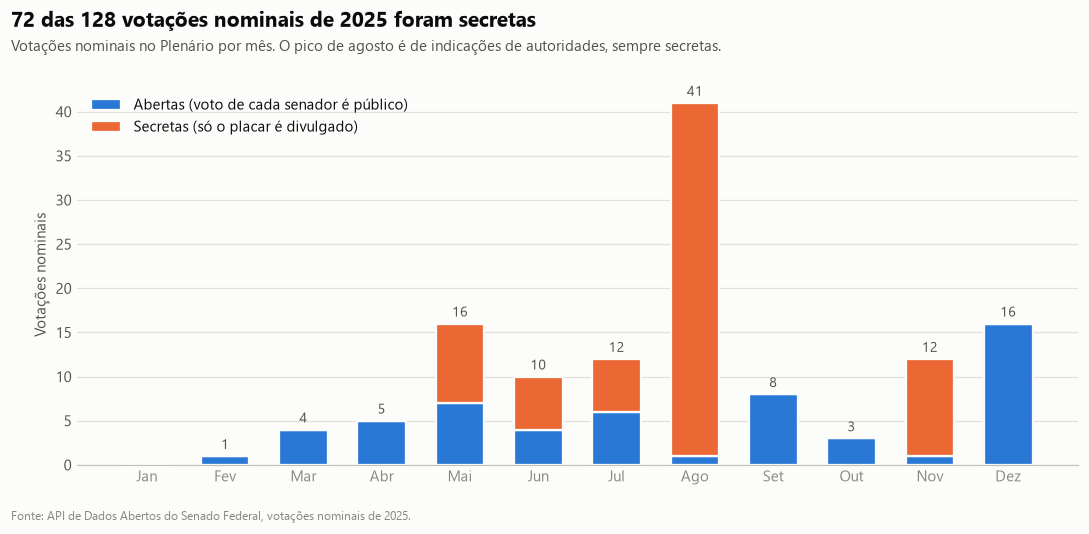

In [16]:
# Dados: nº de votações por mês, separadas em abertas (False) e secretas (True).
# reindex garante os 12 meses no eixo, mesmo os que não tiveram votação (ex.: janeiro)
mensal = (votacoes.assign(mes=votacoes["data"].dt.month)
          .pivot_table(index="mes", columns="secreta", values="id_votacao", aggfunc="count", fill_value=0)
          .reindex(range(1, 13), fill_value=0))
n_secretas, n_total = int(votacoes["secreta"].sum()), len(votacoes)

fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(12)
# barras empilhadas: as secretas começam onde terminam as abertas (bottom=...);
# a borda da cor do fundo cria um pequeno espaço visual entre os dois segmentos
ax.bar(x, mensal[False], width=0.62, color=AZUL, label="Abertas (voto de cada senador é público)",
       edgecolor=SUPERFICIE, linewidth=1.5)
ax.bar(x, mensal[True], width=0.62, bottom=mensal[False], color=LARANJA,
       label="Secretas (só o placar é divulgado)", edgecolor=SUPERFICIE, linewidth=1.5)
# total do mês acima de cada barra
for xi, total in zip(x, mensal.sum(axis=1)):
    if total:
        ax.text(xi, total + 0.8, str(total), ha="center", fontsize=9, color=TINTA_2)
ax.set_xticks(x, MESES)
ax.yaxis.grid(True)
ax.set_axisbelow(True)  # grade atrás das barras
ax.spines["left"].set_visible(False)
ax.set_ylabel("Votações nominais")
ax.legend(loc="upper left", bbox_to_anchor=(0, 1.0), ncols=1)
titulos(fig, f"{n_secretas} das {n_total} votações nominais de 2025 foram secretas",
        "Votações nominais no Plenário por mês. O pico de agosto é de indicações de autoridades, sempre secretas.")
rodape(fig)
fig.subplots_adjust(top=0.84, bottom=0.12, left=0.07, right=0.98)  # margens que abrem espaço para título e rodapé
plt.show()

Em 2025, o Plenário do Senado Federal realizou 128 votações nominais, das quais 72 (56%) foram secretas e 56 (44%) foram abertas. Nas secretas, apenas o placar final é divulgado, já nas abertas, o voto de cada senador é registrado publicamente. A distribuição ao longo do ano é bastante desigual. Agosto concentrou 41 votações, sendo 40 delas secretas, volume associado à apreciação de indicações de autoridades, que por norma regimental são sempre decididas em escrutínio secreto. Maio, junho, julho e novembro também tiveram parcela relevante de votações secretas, enquanto setembro, outubro e dezembro registraram apenas votações abertas, com dezembro somando 16, o segundo maior volume de votações abertas do ano. Janeiro não teve nenhuma votação nominal, pois o período coincide com o recesso parlamentar.

Essa composição define o recorte das análises seguintes. Como o voto de cada senador só é conhecido nas votações abertas, os gráficos sobre consenso (5.2), sobre o comportamento dos blocos conforme quem propôs (5.3) e sobre as votações mais apertadas (5.4) se baseiam nas 56 votações abertas. A exceção é a análise de presença (5.5), que usa as 128, porque a API registra quem estava presente e quem se ausentou mesmo nas votações secretas.

### 5.2 Consenso nas votações abertas

Percentual de votos Sim entre os votos válidos de cada votação aberta. Uma votação pode ser sobre
parte de uma proposta (emenda, destaque, requerimento), então a mesma proposta pode aparecer mais
de uma vez.

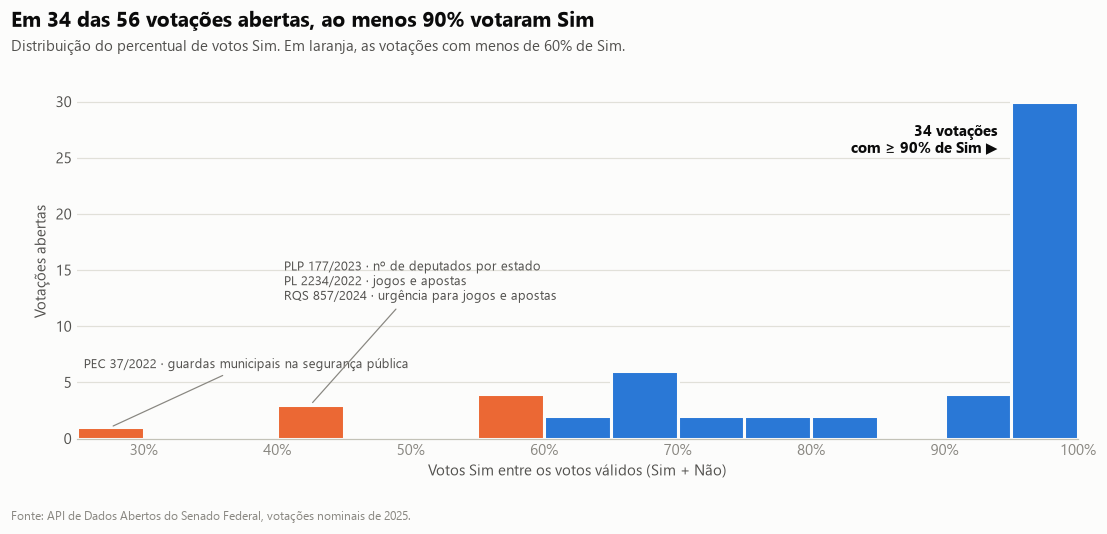

In [17]:
# Nomes curtos das propostas que aparecem em destaque nos gráficos (a ementa é longa demais)
APELIDOS: dict[str, str] = {
    "PEC 37/2022": "guardas municipais na segurança pública",
    "PL 2234/2022": "jogos e apostas",
    "PLP 177/2023": "nº de deputados por estado",
    "PLP 192/2023": "Lei de Inelegibilidade",
    "PL 769/2024": "cargos de polícia judicial no STF",
    "PLP 108/2024": "Comitê Gestor do IBS",
    "RQS 857/2024": "urgência para jogos e apostas",
    "RQS 451/2025": "urgência para nº de deputados",
}

# Dados: % de Sim entre os votos válidos (Sim + Não) de cada votação aberta.
# Abstenções ficam de fora do cálculo, porque não indicam apoio nem oposição.
abertas = votacoes[~votacoes["secreta"]].copy()
abertas["pct_sim"] = (abertas["total_sim"] / (abertas["total_sim"] + abertas["total_nao"])).astype(float) * 100
quase_unanimes = int((abertas["pct_sim"] >= 90).sum())

fig, ax = plt.subplots(figsize=(10, 4.8))
bins = np.arange(25, 105, 5)  # faixas de 5 pontos percentuais: 25-30%, 30-35%, ..., 95-100%
contagem, _, barras = ax.hist(abertas["pct_sim"], bins=bins, color=AZUL, edgecolor=SUPERFICIE, linewidth=2)
for b, borda in zip(barras, bins[:-1]):  # destaca as votações com menos de 60% de Sim
    if borda < 60:
        b.set_facecolor(LARANJA)
ax.set_xlim(25, 100)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.yaxis.grid(True)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Votos Sim entre os votos válidos (Sim + Não)")
ax.set_ylabel("Votações abertas")

# rotula as votações rejeitadas pela maioria, agrupando as que caem na mesma faixa;
# cada grupo de rótulos fica numa altura própria para não haver sobreposição
disputadas = abertas[abertas["pct_sim"] < 50].sort_values("pct_sim")
for i, (faixa, grupo) in enumerate(disputadas.groupby((disputadas["pct_sim"] // 5) * 5)):
    nomes = "\n".join(f"{m} · {APELIDOS.get(m, m)}" for m in grupo["materia"].drop_duplicates())
    altura = contagem[np.searchsorted(bins, faixa, side="right") - 1]  # altura da barra da faixa
    # xy = ponta da linha (topo da barra); xytext = onde fica o texto
    ax.annotate(nomes, xy=(faixa + 2.5, altura), xytext=(faixa + 0.5, 6 + 6 * i), va="bottom",
                fontsize=8.5, color=TINTA_2, arrowprops={"arrowstyle": "-", "color": TINTA_MUTED, "lw": 0.8})
ax.text(94, contagem[-1] - 2, f"{quase_unanimes} votações\ncom ≥ 90% de Sim ▶", ha="right", va="top",
        fontsize=9.5, color=TINTA, fontweight="bold")
titulos(fig, f"Em {quase_unanimes} das {len(abertas)} votações abertas, ao menos 90% votaram Sim",
        "Distribuição do percentual de votos Sim. Em laranja, as votações com menos de 60% de Sim.")
rodape(fig)
fig.subplots_adjust(top=0.84, bottom=0.17, left=0.07, right=0.98)
plt.show()

Nas 53 votações abertas de 2025, o padrão predominante é o consenso. Em 34 delas (64%), ao menos 90% dos votos válidos foram favoráveis, e 25 terminaram sem nenhum voto contrário; a mediana de votos Sim é de 97%. Apenas seis votações ficaram abaixo de 60% de apoio, destacadas em laranja, e só três tiveram mais votos Não do que Sim: uma emenda destacada à PEC 37/2022, que inclui as guardas municipais entre os órgãos de segurança pública (16 a 42), uma emenda destacada ao PLP 177/2023, que redefine o número de deputados por estado (20 a 26), e o requerimento de urgência para o PL 2234/2022, sobre jogos e apostas (28 a 36).

Mesmo os embates mais acirrados do ano ocorreram em votações sobre partes ou procedimentos das propostas, como emendas destacadas e pedidos de urgência, e não sobre o texto principal. Isso sugere que as divergências costumam ser resolvidas antes de a matéria chegar ao Plenário, onde os textos principais são votados quando já há acordo para aprová-los. Há também casos em que a maioria simples não basta: a emenda destacada ao PLP 108/2024, que trata do Comitê Gestor do IBS, recebeu 33 votos Sim contra 27, mas foi rejeitada, porque matérias de lei complementar exigem ao menos 41 votos favoráveis, a maioria absoluta do Senado.

### 5.3 Como cada bloco vota, conforme quem propôs

Percentual de votos **Não** de cada bloco, por grupo de autoria. Quanto mais escuro, mais
resistência. Ficam de fora os senadores sem bloco (NOVO e sem partido, poucos senadores) e a única
votação aberta de "Outros órgãos".

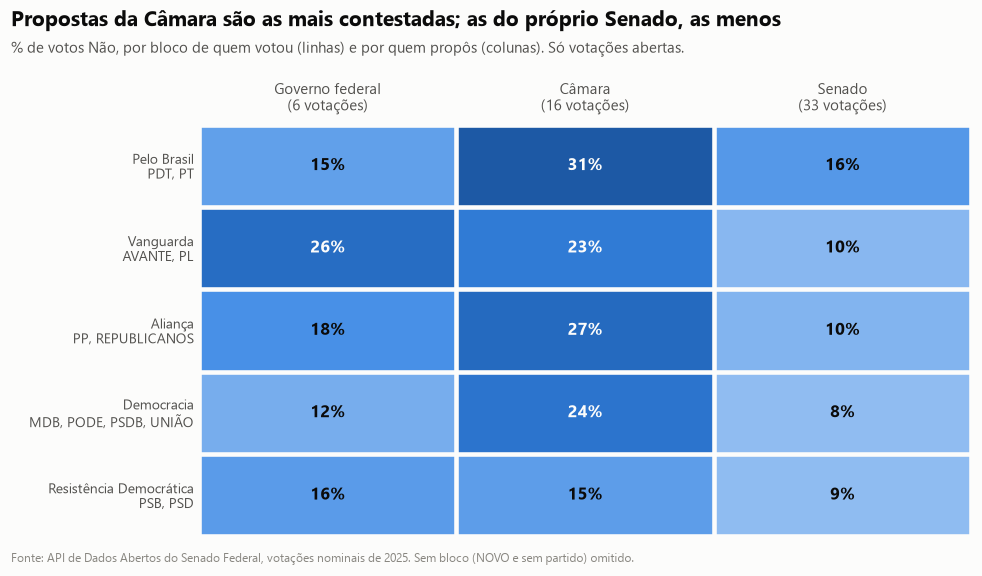

In [18]:
GRUPOS_AUTORIA: list[str] = ["Governo federal", "Câmara", "Senado"]  # 'Outros órgãos' tem 1 votação aberta
# só senadores com bloco e propostas dos três grupos principais
com_bloco_voto = votos_abertos[votos_abertos["bloco"].ne("Sem bloco") & votos_abertos["grupo_autoria"].isin(GRUPOS_AUTORIA)]
# Matriz bloco (linhas) x grupo de autoria (colunas) com o % de votos Não.
# A média de uma coluna True/False é a proporção de True, ou seja, a fração de votos Não.
matriz = (pd.crosstab(com_bloco_voto["bloco"], com_bloco_voto["grupo_autoria"],
                      values=com_bloco_voto["categoria"].eq("Não"), aggfunc="mean")
          .reindex(columns=GRUPOS_AUTORIA) * 100)
matriz = matriz.loc[matriz.mean(axis=1).sort_values(ascending=False).index]  # blocos mais resistentes no topo
n_por_grupo = abertas["grupo_autoria"].value_counts()  # nº de votações por grupo, para o cabeçalho

fig, ax = plt.subplots(figsize=(9, 5.2))
cmap = LinearSegmentedColormap.from_list("azul", RAMPA_AZUL)
# escala fixa de 0% a 40%: o maior valor da matriz é 31%, então nenhuma célula satura
ax.imshow(matriz.to_numpy(dtype=float), cmap=cmap, vmin=0, vmax=40, aspect="auto")
for (i, j), valor in np.ndenumerate(matriz.to_numpy(dtype=float)):
    # texto claro nas células escuras e escuro nas claras, para manter a leitura
    ax.text(j, i, f"{valor:.0f}%", ha="center", va="center", fontsize=11,
            color=SUPERFICIE if valor >= 22 else TINTA, fontweight="bold")
ax.set_xticks(range(len(GRUPOS_AUTORIA)), [f"{g}\n({n_por_grupo[g]} votações)" for g in GRUPOS_AUTORIA])
ax.set_yticks(range(len(matriz)), [ROTULO_BLOCO[b] for b in matriz.index], fontsize=9)
ax.xaxis.tick_top()  # rótulos das colunas em cima, como num cabeçalho de tabela
ax.tick_params(axis="x", colors=TINTA_2, pad=6)
for lado in ax.spines.values():
    lado.set_visible(False)
# linhas da cor do fundo entre as células, para separá-las visualmente
ax.set_xticks(np.arange(-0.5, len(GRUPOS_AUTORIA)), minor=True)
ax.set_yticks(np.arange(-0.5, len(matriz)), minor=True)
ax.grid(which="minor", color=SUPERFICIE, linewidth=3)
ax.tick_params(which="minor", length=0)
titulos(fig, "Propostas da Câmara são as mais contestadas; as do próprio Senado, as menos",
        "% de votos Não, por bloco de quem votou (linhas) e por quem propôs (colunas). Só votações abertas.")
rodape(fig, "Sem bloco (NOVO e sem partido) omitido.")
fig.subplots_adjust(top=0.78, bottom=0.06, left=0.2, right=0.98)
plt.show()

O mapa cruza os grupos de quem votou, organizado pelos blocos parlamentares, e de quem propôs a matéria, dividido entre Governo federal, Câmara dos Deputados e o próprio Senado. Cada célula indica a parcela de votos Não daquele bloco nas votações abertas de propostas daquele grupo. No conjunto, as propostas do Senado são as que encontram menos resistência (10% de votos Não), seguidas das do Governo federal (16%) e das da Câmara (20%). A rejeição às propostas da própria Casa é baixa em todos os blocos, entre 8% e 14%, o que reforça o padrão de consenso observado nas votações abertas: o que os senadores propõem costuma chegar ao Plenário já negociado.

As diferenças entre os blocos ajudam a ler o posicionamento político de cada um. A Vanguarda, que reúne o PL, principal partido de oposição, é o bloco que mais rejeita as propostas do Governo federal (26%), enquanto a Democracia, formada por MDB, Podemos, PSDB e União, é a que menos as rejeita (12%). Já o Pelo Brasil, bloco do PT, partido do presidente da República, tem comportamento oposto: apoia as propostas do Governo (15% de votos Não) e é o mais resistente às que vêm da Câmara (27%), casa em que o governo não tem maioria consolidada. Esses números devem ser lidos com cautela, porque a coluna do Governo reúne apenas seis votações, algumas delas sobre emendas e destaques, e não sobre o texto principal das propostas.

### 5.4 Quem votou a favor e contra nas votações mais apertadas

As quatro votações abertas com a menor diferença entre Sim e Não, uma por proposta. Requerimentos e
questões de ordem ficam de fora, porque nelas o Sim e o Não se referem a procedimentos e não ao
conteúdo da proposta.

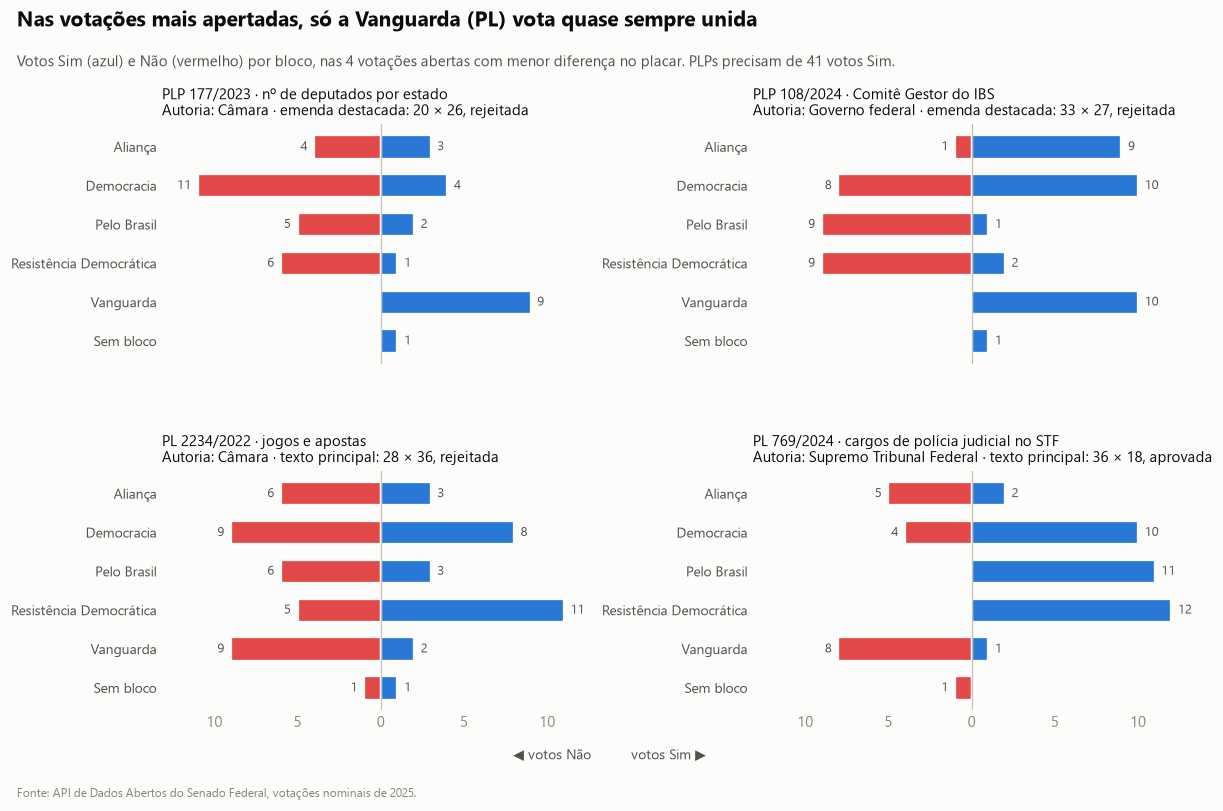

In [19]:
def objeto_votado(descricao: str) -> str:
    """Uma votação pode ser sobre parte da proposta; resume o que foi votado a partir da descrição."""
    d = descricao.lower()
    if "questão de ordem" in d:
        return "Questão de ordem"
    if "destacada" in d:
        return "Emenda destacada"
    if "emenda" in d or "substitutivo" in d:
        return "Substitutivo ou emenda"
    return "Texto principal"


# as 4 votações mais apertadas (menor diferença entre Sim e Não), uma por proposta; ficam de fora
# requerimentos e questões de ordem, em que Sim/Não se referem a procedimentos e não à proposta
apertadas = (abertas[abertas["tipo_materia"].ne("RQS")
                     & abertas["descricao"].map(objeto_votado).ne("Questão de ordem")]
             .assign(margem=lambda d: (d["total_sim"] - d["total_nao"]).abs())
             .sort_values("margem").drop_duplicates("id_processo").head(4))
ordem_blocos = [*sorted(set(PARTIDO_BLOCO.values())), "Sem bloco"]  # mesma ordem em todos os painéis

# Um painel por votação (grade 2 x 2). Em cada um, barras divergentes a partir do zero:
# votos Não para a esquerda (valores negativos) e Sim para a direita
fig, eixos = plt.subplots(2, 2, figsize=(11, 7.4), sharex=True)
for ax, (_, v) in zip(eixos.flat, apertadas.iterrows()):
    # placar por bloco nesta votação: linhas = blocos, colunas = Sim e Não
    placar = (votos_abertos[votos_abertos["id_votacao"].eq(v["id_votacao"])]
              .groupby(["bloco", "categoria"], observed=True).size().unstack(fill_value=0)
              .reindex(index=ordem_blocos, columns=["Sim", "Não"], fill_value=0))
    y = np.arange(len(placar))[::-1]  # invertido para o primeiro bloco ficar no topo
    ax.barh(y, -placar["Não"], color=VERMELHO, height=0.6, edgecolor=SUPERFICIE, linewidth=1.5)
    ax.barh(y, placar["Sim"], color=AZUL, height=0.6, edgecolor=SUPERFICIE, linewidth=1.5)
    # número de votos na ponta de cada barra (só quando há votos)
    for yi, (sim, nao) in zip(y, placar[["Sim", "Não"]].to_numpy()):
        if nao:
            ax.text(-nao - 0.4, yi, str(nao), ha="right", va="center", fontsize=8.5, color=TINTA_2)
        if sim:
            ax.text(sim + 0.4, yi, str(sim), ha="left", va="center", fontsize=8.5, color=TINTA_2)
    ax.axvline(0, color=EIXO, linewidth=0.8)  # linha do zero, que divide Não e Sim
    ax.set_yticks(y, placar.index, fontsize=9)
    ax.spines[["left", "bottom"]].set_visible(False)
    ax.xaxis.set_major_formatter(lambda val, _: f"{abs(val):.0f}")  # o lado do Não aparece sem sinal negativo
    resultado = "aprovada" if v["aprovada"] else "rejeitada"
    # para "Outros órgãos", o nome do autor (ex.: STF) é mais informativo que o grupo
    ax.set_title(f"{v['materia']} · {APELIDOS.get(v['materia'], v['materia'])}\n"
                 f"Autoria: {v['autor_principal'] if v['grupo_autoria'] == 'Outros órgãos' else v['grupo_autoria']}"
                 f" · {objeto_votado(v['descricao']).lower()}: {v['total_sim']} × {v['total_nao']}, {resultado}",
                 loc="left", fontsize=9.5, color=TINTA)
# mesma escala horizontal e simétrica em todos os painéis, para que sejam comparáveis
lim = max(abs(a) for ax in eixos.flat for a in ax.get_xlim())
for ax in eixos.flat:
    ax.set_xlim(-lim, lim)
fig.text(0.5, 0.06, "◀ votos Não          votos Sim ▶", ha="center", fontsize=9, color=TINTA_2)
titulos(fig, "Nas votações mais apertadas, só a Vanguarda (PL) vota quase sempre unida",
        "Votos Sim (azul) e Não (vermelho) por bloco, nas 4 votações abertas com menor diferença no placar. "
        "PLPs precisam de 41 votos Sim.")
rodape(fig)
fig.subplots_adjust(top=0.84, bottom=0.12, left=0.13, right=0.98, hspace=0.45, wspace=0.35)
plt.show()

O gráfico detalha, bloco a bloco, as quatro votações abertas com a menor diferença entre votos Sim e Não, excluídos requerimentos e questões de ordem, em que o voto se refere a procedimentos, e não ao conteúdo da proposta. Três delas trataram de emendas destacadas, e não do texto principal: a emenda ao PLP 177/2023, que redefine o número de deputados por estado, rejeitada por 20 a 26; a emenda ao PLP 108/2024, que cria o Comitê Gestor do IBS, rejeitada mesmo com 33 votos Sim contra 27, por não alcançar os 41 votos exigidos para leis complementares; e a emenda à MPV 1291/2025, sobre o Fundo Social, aprovada por 37 a 17. A quarta foi o PL 769/2024, de autoria do Supremo Tribunal Federal, que cria cargos de polícia judicial na Corte, aprovado por 36 a 18.

Nas quatro votações, a Vanguarda, bloco do PL, e o Pelo Brasil, bloco do PT, ficaram em lados opostos, ambos com alto grau de unidade: a Vanguarda deu no máximo um voto divergente em cada votação, e o Pelo Brasil votou integralmente unido em duas delas. Os demais blocos mostram comportamento menos previsível. A Democracia, maior bloco do Senado, dividiu-se na emenda ao PLP 108/2024 (10 votos Sim e 8 Não) e acompanhou lados diferentes conforme a matéria, o que a coloca como fiel da balança nas disputas mais equilibradas. O padrão sugere que, quando há polarização no Plenário, ela se organiza em torno do eixo entre governo e oposição, representados pelos dois blocos dos extremos, enquanto o centro decide o resultado.

### 5.5 Presença e participação

Situação de cada senador em cada uma das 128 votações nominais: votou, esteve presente sem votar
(inclui quem presidia a sessão), ausente com justificativa (missão, atividade parlamentar ou
licença) ou ausente sem justificativa.

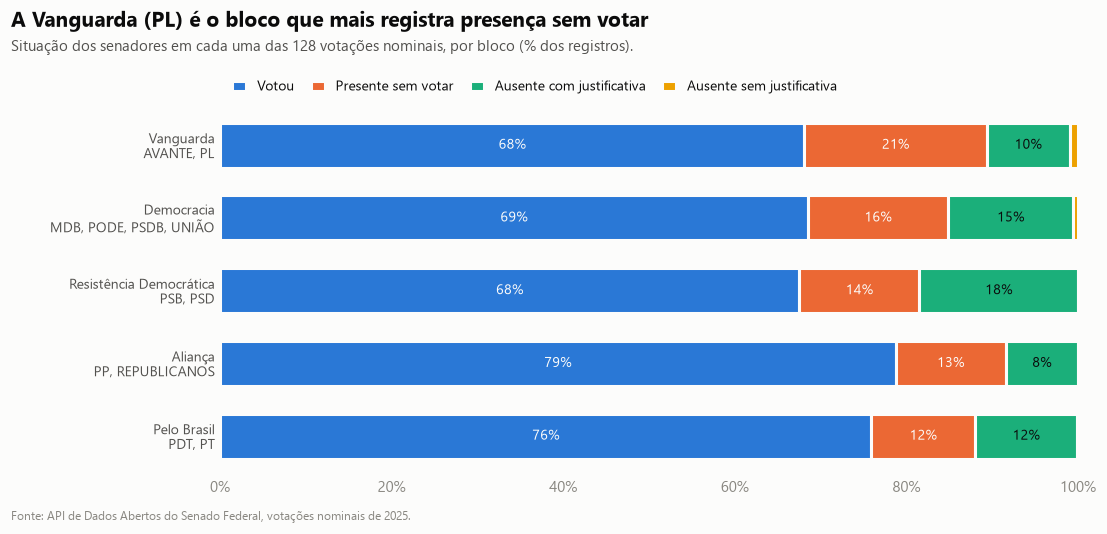

In [20]:
# Agrupa as categorias de voto em 4 situações de presença
PRESENCA: dict[str, str] = {
    "Sim": "Votou", "Não": "Votou", "Abstenção": "Votou", "Votou (secreta)": "Votou",
    "Presidindo a sessão": "Presente sem votar", "Presente sem voto": "Presente sem votar",
    "Ausência justificada": "Ausente com justificativa", "Licença": "Ausente com justificativa",
    "Ausente sem justificativa": "Ausente sem justificativa",
}
ORDEM_PRESENCA = ["Votou", "Presente sem votar", "Ausente com justificativa", "Ausente sem justificativa"]
CORES_PRESENCA = [AZUL, LARANJA, AQUA, AMARELO]  # uma cor por situação, na mesma ordem

# Dados: % de cada situação dentro de cada bloco (normalize="index" faz cada linha somar 100%)
presenca = (votos.assign(situacao=votos["categoria"].map(PRESENCA))
            .dropna(subset=["situacao"])  # 'Não se aplica' não é presença nem ausência: fica de fora
            .pipe(lambda d: pd.crosstab(d["bloco"], d["situacao"], normalize="index"))
            .reindex(columns=ORDEM_PRESENCA, fill_value=0) * 100)
# ordena pelo % de presença sem voto; com barh, o último da lista aparece no topo
presenca = presenca.drop(index="Sem bloco", errors="ignore").sort_values("Presente sem votar")

fig, ax = plt.subplots(figsize=(10, 4.8))
esquerda = np.zeros(len(presenca))  # onde começa o próximo segmento de cada barra
y = np.arange(len(presenca))
# barras 100% empilhadas: cada situação é desenhada a partir do fim da anterior
for situacao, cor in zip(ORDEM_PRESENCA, CORES_PRESENCA):
    valores = presenca[situacao].to_numpy()
    ax.barh(y, valores, left=esquerda, color=cor, height=0.62, label=situacao, edgecolor=SUPERFICIE, linewidth=2)
    for yi, (ini, val) in enumerate(zip(esquerda, valores)):
        if val >= 5:  # só rotula o segmento quando o texto cabe; os demais valores estão na tabela abaixo
            ax.text(ini + val / 2, yi, f"{val:.0f}%", ha="center", va="center", fontsize=9,
                    color=SUPERFICIE if cor in (AZUL, LARANJA) else TINTA)  # contraste com a cor do segmento
    esquerda += valores
ax.set_yticks(y, [ROTULO_BLOCO[b] for b in presenca.index], fontsize=9)
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.spines[["left", "bottom"]].set_visible(False)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncols=4, fontsize=9, handlelength=1, columnspacing=1.2)
titulos(fig, "A Vanguarda (PL) é o bloco que mais registra presença sem votar",
        "Situação dos senadores em cada uma das 128 votações nominais, por bloco (% dos registros).")
rodape(fig)
fig.subplots_adjust(top=0.8, bottom=0.1, left=0.2, right=0.98)
plt.show()

O gráfico mostra a situação de cada senador em cada votação nominal do ano, agrupada por blocos de acordo com seus votos, presenças e justificativas. As faltas sem justificativa são raras em todos os blocos, sempre abaixo de 1% dos registros, o que indica que as ausências no Senado são quase sempre formalizadas. A Aliança, formada por PP e Republicanos, é o bloco mais participativo, com 79% de votos registrados e a menor taxa de ausências justificadas (9%). No extremo oposto, a Resistência Democrática, de PSB e PSD, tem a maior parcela de ausências justificadas (19%).

O destaque é a Vanguarda, bloco do PL, em que 21% dos registros são de senadores presentes que não votaram, ante 12% a 16% nos demais blocos. A diferença se concentra nas votações secretas, que em 2025 foram todas de indicações de autoridades feitas pelo Poder Executivo ou por outros órgãos: nelas, a Vanguarda teve 29% de presença sem voto, contra 16% a 21% nos demais blocos. Nas votações abertas, a distância é menor (11% contra 6% a 10%). O padrão é compatível com uma estratégia de não participar da aprovação de nomes indicados pelo governo, embora os dados não permitam confirmar a motivação. A taxa de 16% da Democracia também merece contexto: ela inclui o presidente do Senado, Davi Alcolumbre, que pertence ao bloco e, ao presidir as sessões, não vota.

In [21]:
presenca.round(1)  

situacao,Votou,Presente sem votar,Ausente com justificativa,Ausente sem justificativa
bloco,,,,
Pelo Brasil,75.9,12.0,12.0,0.1
Aliança,78.7,12.8,8.4,0.0
Resistência Democrática,67.5,14.0,18.5,0.0
Democracia,68.5,16.3,14.6,0.6
Vanguarda,68.1,21.2,9.7,1.0
